In [1]:
!pip install requests pandas matplotlib seaborn

In [2]:
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from time import sleep
from datetime import datetime

In [3]:
API_KEY = "16981d08acae48dbbd1a11cb45acd843"

URL = "https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest"

PARAMETERS = {
    "start": 1,
    "limit": 15,
    "convert": "USD"
}

HEADERS = {
    "Accepts": "application/json",
    "X-CMC_PRO_API_KEY": API_KEY
}


In [4]:
def get_crypto_data():
    
    try:
        response = requests.get(
            URL,
            headers=HEADERS,
            params=PARAMETERS,
            timeout=10
        )
        
        response.raise_for_status()
        
        data = response.json()
        
        if "data" not in data:
            print("API response does not contain data.")
            return pd.DataFrame()
        
        df = pd.json_normalize(data["data"])
        
        return df
    
    except requests.exceptions.Timeout:
        print("The request timed out.")
        return pd.DataFrame()
    
    except requests.exceptions.ConnectionError:
        print("Connection error. Check your internet connection.")
        return pd.DataFrame()
    
    except requests.exceptions.HTTPError as e:
        print(f"HTTP error: {e}")
        return pd.DataFrame()
    
    except Exception as e:
        print(f"Something went wrong: {e}")
        return pd.DataFrame()


In [5]:
df = get_crypto_data()

df.head()


,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,...,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address
0,1,Bitcoin,BTC,bitcoin,False,2.009398e+07,2.009398e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12755,...,1.725821e+12,58.9666,1.803637e+12,None,2026-10-05T21:50:00.000Z,NaN,NaN,NaN,NaN,NaN
1,1027,Ethereum,ETH,ethereum,True,1.221075e+08,1.221075e+08,NaN,2015-08-07T00:00:00.000Z,13930,...,3.315653e+11,11.3287,3.315653e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN
2,825,Tether USDt,USDT,tether,True,1.840883e+11,1.893195e+11,NaN,2015-02-25T00:00:00.000Z,203011,...,1.840521e+11,6.2886,1.892824e+11,None,2026-10-05T21:49:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7
3,1839,BNB,BNB,bnb,False,1.331590e+08,1.331590e+08,1.331590e+08,2017-07-25T00:00:00.000Z,3497,...,1.047048e+11,3.5775,1.047048e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN
4,52,XRP,XRP,xrp,False,6.309298e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,...,9.499010e+10,3.2456,1.505557e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 15
Columns: 39
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 39 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  15 non-null     int64  
 1   name                                15 non-null     str    
 2   symbol                              15 non-null     str    
 3   slug                                15 non-null     str    
 4   infinite_supply                     15 non-null     bool   
 5   circulating_supply                  15 non-null     float64
 6   total_supply                        15 non-null     float64
 7   max_supply                          7 non-null      float64
 8   date_added                          15 non-null     str    
 9   num_market_pairs                    15 non-null     int64  
 10  cmc_rank                            15 non-null     int64  
 11  last_updated                        1

In [7]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

df.head()

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address
0,1,Bitcoin,BTC,bitcoin,False,2.009398e+07,2.009398e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12755,1,2026-10-05T21:50:00.000Z,None,NaN,NaN,NaN,1.725821e+12,"[mineable, pow, sha-256, store-of-value, state...",85887.459169,3.232441e+10,3.229204e+10,3.236804e+07,151.1707,0.093566,-0.061572,3.038940,7.476826,33.373277,35.325570,1.725821e+12,58.9666,1.803637e+12,None,2026-10-05T21:50:00.000Z,NaN,NaN,NaN,NaN,NaN
1,1027,Ethereum,ETH,ethereum,True,1.221075e+08,1.221075e+08,NaN,2015-08-07T00:00:00.000Z,13930,2,2026-10-05T21:49:00.000Z,None,NaN,NaN,NaN,3.315653e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2715.355050,1.346344e+10,1.326778e+10,1.956573e+08,191.5851,0.046246,0.310122,1.421334,9.020746,42.536079,52.870043,3.315653e+11,11.3287,3.315653e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN
2,825,Tether USDt,USDT,tether,True,1.840883e+11,1.893195e+11,NaN,2015-02-25T00:00:00.000Z,203011,3,2026-10-05T21:49:00.000Z,None,NaN,NaN,NaN,1.892824e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999804,7.437200e+10,7.316192e+10,1.210083e+09,114.4688,-0.001092,-0.000398,0.029997,-0.025596,0.071887,0.039711,1.840521e+11,6.2886,1.892824e+11,None,2026-10-05T21:49:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7
3,1839,BNB,BNB,bnb,False,1.331590e+08,1.331590e+08,1.331590e+08,2017-07-25T00:00:00.000Z,3497,4,2026-10-05T21:49:00.000Z,None,NaN,NaN,NaN,1.047048e+11,"[marketplace, centralized-exchange, payments, ...",786.314155,1.690696e+09,1.660493e+09,3.020355e+07,49.3560,-0.183011,-0.965102,3.222906,1.865441,32.865088,35.920310,1.047048e+11,3.5775,1.047048e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN
4,52,XRP,XRP,xrp,False,6.309298e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,5,2026-10-05T21:49:00.000Z,None,NaN,NaN,NaN,1.505341e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.505557,2.414141e+09,2.413055e+09,1.085866e+06,103.8075,0.035208,-0.334622,1.224229,5.925375,45.471747,35.087590,9.499010e+10,3.2456,1.505557e+11,None,2026-10-05T21:49:00.000Z,NaN,NaN,NaN,NaN,NaN


In [8]:
df["timestamp"] = pd.Timestamp.now()

df[["name", "symbol", "timestamp"]].head()

,name,symbol,timestamp
0,Bitcoin,BTC,2026-10-06 00:51:11.400903
1,Ethereum,ETH,2026-10-06 00:51:11.400903
2,Tether USDt,USDT,2026-10-06 00:51:11.400903
3,BNB,BNB,2026-10-06 00:51:11.400903
4,XRP,XRP,2026-10-06 00:51:11.400903


In [9]:
columns = [
    "id",
    "name",
    "symbol",
    "cmc_rank",
    "quote.USD.price",
    "quote.USD.market_cap",
    "quote.USD.volume_24h",
    "quote.USD.percent_change_1h",
    "quote.USD.percent_change_24h",
    "quote.USD.percent_change_7d",
    "quote.USD.percent_change_30d",
    "timestamp"
]

crypto_df = df[columns].copy()

crypto_df.head()


,id,name,symbol,cmc_rank,quote.USD.price,quote.USD.market_cap,quote.USD.volume_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903
1,1027,Ethereum,ETH,2,2715.355050,3.315653e+11,1.346344e+10,0.046246,0.310122,1.421334,9.020746,2026-10-06 00:51:11.400903
2,825,Tether USDt,USDT,3,0.999804,1.840521e+11,7.437200e+10,-0.001092,-0.000398,0.029997,-0.025596,2026-10-06 00:51:11.400903
3,1839,BNB,BNB,4,786.314155,1.047048e+11,1.690696e+09,-0.183011,-0.965102,3.222906,1.865441,2026-10-06 00:51:11.400903
4,52,XRP,XRP,5,1.505557,9.499010e+10,2.414141e+09,0.035208,-0.334622,1.224229,5.925375,2026-10-06 00:51:11.400903


In [10]:
crypto_df.head()


,id,name,symbol,cmc_rank,quote.USD.price,quote.USD.market_cap,quote.USD.volume_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903
1,1027,Ethereum,ETH,2,2715.355050,3.315653e+11,1.346344e+10,0.046246,0.310122,1.421334,9.020746,2026-10-06 00:51:11.400903
2,825,Tether USDt,USDT,3,0.999804,1.840521e+11,7.437200e+10,-0.001092,-0.000398,0.029997,-0.025596,2026-10-06 00:51:11.400903
3,1839,BNB,BNB,4,786.314155,1.047048e+11,1.690696e+09,-0.183011,-0.965102,3.222906,1.865441,2026-10-06 00:51:11.400903
4,52,XRP,XRP,5,1.505557,9.499010e+10,2.414141e+09,0.035208,-0.334622,1.224229,5.925375,2026-10-06 00:51:11.400903


In [11]:
crypto_df = crypto_df.rename(columns={
    "quote.USD.price": "price_usd",
    "quote.USD.market_cap": "market_cap_usd",
    "quote.USD.volume_24h": "volume_24h_usd",
    "quote.USD.percent_change_1h": "change_1h",
    "quote.USD.percent_change_24h": "change_24h",
    "quote.USD.percent_change_7d": "change_7d",
    "quote.USD.percent_change_30d": "change_30d"
})


In [12]:
crypto_df.head()


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903
1,1027,Ethereum,ETH,2,2715.355050,3.315653e+11,1.346344e+10,0.046246,0.310122,1.421334,9.020746,2026-10-06 00:51:11.400903
2,825,Tether USDt,USDT,3,0.999804,1.840521e+11,7.437200e+10,-0.001092,-0.000398,0.029997,-0.025596,2026-10-06 00:51:11.400903
3,1839,BNB,BNB,4,786.314155,1.047048e+11,1.690696e+09,-0.183011,-0.965102,3.222906,1.865441,2026-10-06 00:51:11.400903
4,52,XRP,XRP,5,1.505557,9.499010e+10,2.414141e+09,0.035208,-0.334622,1.224229,5.925375,2026-10-06 00:51:11.400903


In [13]:
crypto_df.isna().sum()


id                0
name              0
symbol            0
cmc_rank          0
price_usd         0
market_cap_usd    0
volume_24h_usd    0
change_1h         0
change_24h        0
change_7d         0
change_30d        0
timestamp         0
dtype: int64

In [14]:
crypto_df[crypto_df.isna().any(axis=1)]


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp


In [15]:
crypto_df = crypto_df.drop_duplicates()

crypto_df["name"] = crypto_df["name"].str.strip()
crypto_df["symbol"] = crypto_df["symbol"].str.strip()

In [16]:
crypto_df.head()


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903
1,1027,Ethereum,ETH,2,2715.355050,3.315653e+11,1.346344e+10,0.046246,0.310122,1.421334,9.020746,2026-10-06 00:51:11.400903
2,825,Tether USDt,USDT,3,0.999804,1.840521e+11,7.437200e+10,-0.001092,-0.000398,0.029997,-0.025596,2026-10-06 00:51:11.400903
3,1839,BNB,BNB,4,786.314155,1.047048e+11,1.690696e+09,-0.183011,-0.965102,3.222906,1.865441,2026-10-06 00:51:11.400903
4,52,XRP,XRP,5,1.505557,9.499010e+10,2.414141e+09,0.035208,-0.334622,1.224229,5.925375,2026-10-06 00:51:11.400903


In [17]:
numeric_columns = [
    "cmc_rank",
    "price_usd",
    "market_cap_usd",
    "volume_24h_usd",
    "change_1h",
    "change_24h",
    "change_7d",
    "change_30d"
]

crypto_df[numeric_columns] = crypto_df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

In [18]:
crypto_df.dtypes


id                         int64
name                         str
symbol                       str
cmc_rank                   int64
price_usd                float64
market_cap_usd           float64
volume_24h_usd           float64
change_1h                float64
change_24h               float64
change_7d                float64
change_30d               float64
timestamp         datetime64[us]
dtype: object

In [19]:
crypto_df


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903
1,1027,Ethereum,ETH,2,2715.355050,3.315653e+11,1.346344e+10,0.046246,0.310122,1.421334,9.020746,2026-10-06 00:51:11.400903
2,825,Tether USDt,USDT,3,0.999804,1.840521e+11,7.437200e+10,-0.001092,-0.000398,0.029997,-0.025596,2026-10-06 00:51:11.400903
3,1839,BNB,BNB,4,786.314155,1.047048e+11,1.690696e+09,-0.183011,-0.965102,3.222906,1.865441,2026-10-06 00:51:11.400903
4,52,XRP,XRP,5,1.505557,9.499010e+10,2.414141e+09,0.035208,-0.334622,1.224229,5.925375,2026-10-06 00:51:11.400903
5,3408,USDC,USDC,6,0.999818,7.421582e+10,1.726405e+10,-0.002622,-0.014252,-0.018561,-0.008567,2026-10-06 00:51:11.400903
6,5426,Solana,SOL,7,120.647667,7.098723e+10,2.527902e+09,0.093589,-0.667794,2.254524,16.131495,2026-10-06 00:51:11.400903
7,1958,TRON,TRX,8,0.336314,3.194435e+10,4.006232e+08,-0.028482,0.183132,0.200399,0.480543,2026-10-06 00:51:11.400903
8,32196,Hyperliquid,HYPE,9,94.697544,2.373358e+10,1.169450e+09,-0.072386,4.281515,8.994867,10.462494,2026-10-06 00:51:11.400903
9,1437,Zcash,ZEC,10,1348.889689,2.279961e+10,9.326215e+08,0.071119,0.774877,-7.748786,32.830383,2026-10-06 00:51:11.400903


In [20]:
print("=" * 65)
print("              CRYPTO MARKET OVERVIEW")
print("=" * 65)

print()

print(
    f"Cryptocurrencies analyzed : "
    f"{crypto_df['name'].nunique()}"
)

print(
    f"Total market capitalization: "
    f"${crypto_df['market_cap_usd'].sum():,.2f}"
)

print(
    f"Total 24h trading volume  : "
    f"${crypto_df['volume_24h_usd'].sum():,.2f}"
)

print()

print("=" * 65)


              CRYPTO MARKET OVERVIEW

Cryptocurrencies analyzed : 15
Total market capitalization: $2,720,292,101,711.91
Total 24h trading volume  : $149,229,001,445.73



In [21]:
top_market_cap = (
    crypto_df
    .sort_values(
        "market_cap_usd",
        ascending=False
    )
)

top_market_cap[
    [
        "cmc_rank",
        "name",
        "symbol",
        "price_usd",
        "market_cap_usd"
    ]
]


,cmc_rank,name,symbol,price_usd,market_cap_usd
0,1,Bitcoin,BTC,85887.459169,1.725821e+12
1,2,Ethereum,ETH,2715.355050,3.315653e+11
2,3,Tether USDt,USDT,0.999804,1.840521e+11
3,4,BNB,BNB,786.314155,1.047048e+11
4,5,XRP,XRP,1.505557,9.499010e+10
5,6,USDC,USDC,0.999818,7.421582e+10
6,7,Solana,SOL,120.647667,7.098723e+10
7,8,TRON,TRX,0.336314,3.194435e+10
8,9,Hyperliquid,HYPE,94.697544,2.373358e+10
9,10,Zcash,ZEC,1348.889689,2.279961e+10


In [22]:
top_10 = (
    crypto_df
    .sort_values(
        "market_cap_usd",
        ascending=False
    )
    .head(10)
)

top_10[
    [
        "name",
        "symbol",
        "price_usd",
        "market_cap_usd"
    ]
]


,name,symbol,price_usd,market_cap_usd
0,Bitcoin,BTC,85887.459169,1.725821e+12
1,Ethereum,ETH,2715.355050,3.315653e+11
2,Tether USDt,USDT,0.999804,1.840521e+11
3,BNB,BNB,786.314155,1.047048e+11
4,XRP,XRP,1.505557,9.499010e+10
5,USDC,USDC,0.999818,7.421582e+10
6,Solana,SOL,120.647667,7.098723e+10
7,TRON,TRX,0.336314,3.194435e+10
8,Hyperliquid,HYPE,94.697544,2.373358e+10
9,Zcash,ZEC,1348.889689,2.279961e+10


In [23]:
best_24h = (
    crypto_df
    .sort_values(
        "change_24h",
        ascending=False
    )
)

best_24h[
    [
        "name",
        "symbol",
        "change_24h"
    ]
]


,name,symbol,change_24h
13,Cardano,ADA,6.374575
8,Hyperliquid,HYPE,4.281515
11,Monero,XMR,1.756191
9,Zcash,ZEC,0.774877
1,Ethereum,ETH,0.310122
7,TRON,TRX,0.183132
2,Tether USDt,USDT,-0.000398
5,USDC,USDC,-0.014252
0,Bitcoin,BTC,-0.061572
4,XRP,XRP,-0.334622


In [24]:
worst_24h = (
    crypto_df
    .sort_values(
        "change_24h"
    )
)

worst_24h[
    [
        "name",
        "symbol",
        "change_24h"
    ]
]

,name,symbol,change_24h
12,Chainlink,LINK,-1.955737
10,Dogecoin,DOGE,-1.560377
3,BNB,BNB,-0.965102
14,UNUS SED LEO,LEO,-0.678086
6,Solana,SOL,-0.667794
4,XRP,XRP,-0.334622
0,Bitcoin,BTC,-0.061572
5,USDC,USDC,-0.014252
2,Tether USDt,USDT,-0.000398
7,TRON,TRX,0.183132


In [25]:
best_7d = (
    crypto_df
    .sort_values(
        "change_7d",
        ascending=False
    )
)

best_7d[
    [
        "name",
        "symbol",
        "change_7d"
    ]
]

,name,symbol,change_7d
13,Cardano,ADA,10.286667
8,Hyperliquid,HYPE,8.994867
11,Monero,XMR,4.322174
3,BNB,BNB,3.222906
0,Bitcoin,BTC,3.038940
10,Dogecoin,DOGE,2.376954
6,Solana,SOL,2.254524
1,Ethereum,ETH,1.421334
4,XRP,XRP,1.224229
7,TRON,TRX,0.200399


In [26]:
bitcoin = crypto_df[
    crypto_df["symbol"] == "BTC"
].copy()

bitcoin

,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.03894,7.476826,2026-10-06 00:51:11.400903


In [27]:
if not bitcoin.empty:
    
    btc = bitcoin.iloc[0]
    
    print("=" * 65)
    print("                    BITCOIN")
    print("=" * 65)
    
    print()
    print(f"Price              : ${btc['price_usd']:,.2f}")
    print(f"Market Cap         : ${btc['market_cap_usd']:,.2f}")
    print(f"24h Volume         : ${btc['volume_24h_usd']:,.2f}")
    
    print()
    print(f"1 Hour Change      : {btc['change_1h']:.2f}%")
    print(f"24 Hour Change     : {btc['change_24h']:.2f}%")
    print(f"7 Day Change       : {btc['change_7d']:.2f}%")
    print(f"30 Day Change      : {btc['change_30d']:.2f}%")
    
    print()
    print("=" * 65)

else:
    print("Bitcoin was not found.")

                    BITCOIN

Price              : $85,887.46
Market Cap         : $1,725,820,715,009.87
24h Volume         : $32,324,411,103.07

1 Hour Change      : 0.09%
24 Hour Change     : -0.06%
7 Day Change       : 3.04%
30 Day Change      : 7.48%



In [28]:
sns.set_theme(style="darkgrid")


In [29]:
plt.rcParams["figure.figsize"] = (12, 6)

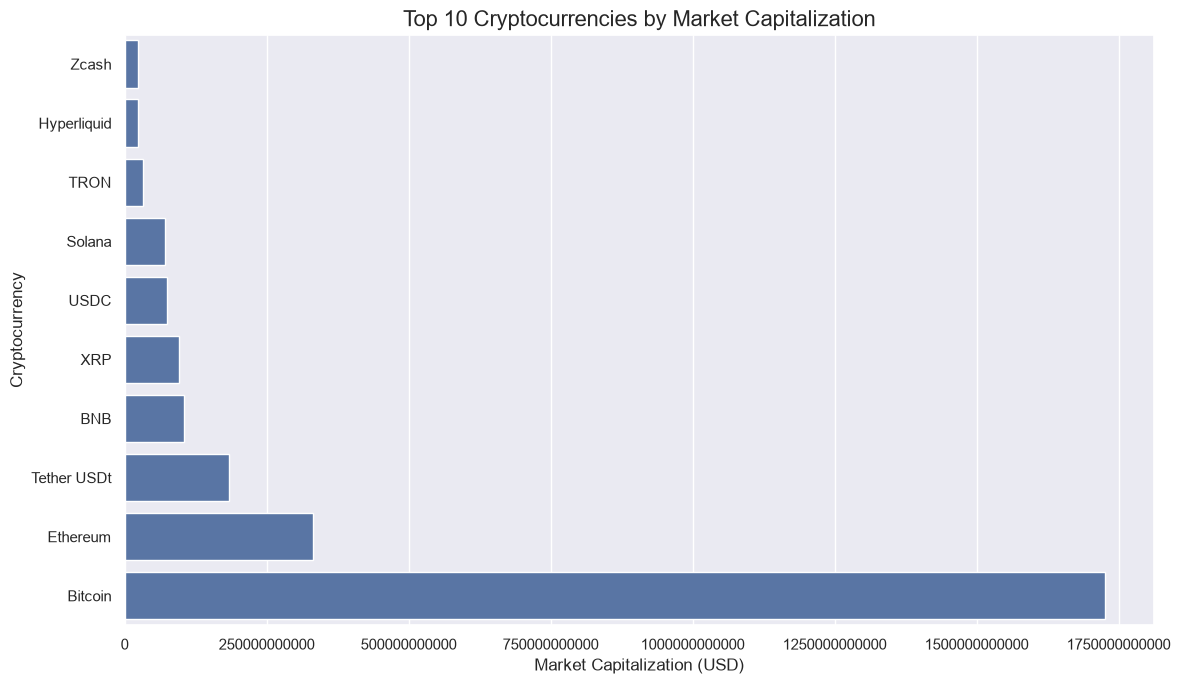

In [30]:
plt.figure(figsize=(12, 7))

plot_data = top_10.sort_values(
    "market_cap_usd",
    ascending=True
)

sns.barplot(
    data=plot_data,
    x="market_cap_usd",
    y="name"
)

plt.title(
    "Top 10 Cryptocurrencies by Market Capitalization",
    fontsize=16
)

plt.xlabel("Market Capitalization (USD)")
plt.ylabel("Cryptocurrency")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()


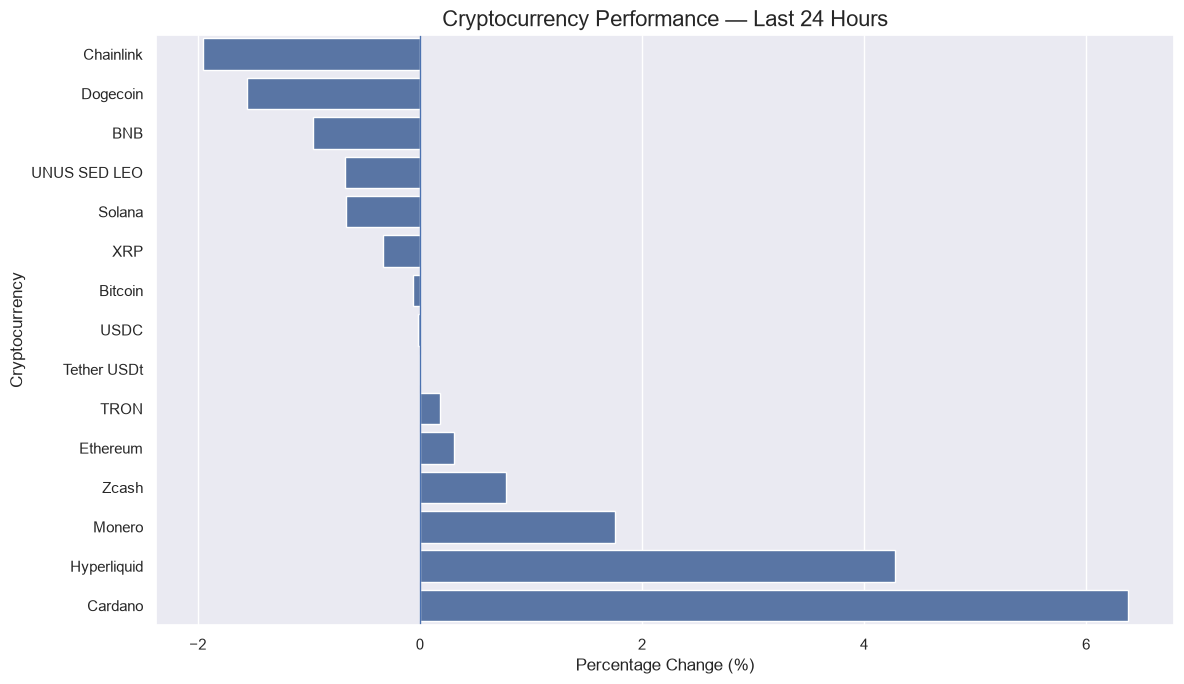

In [31]:
plt.figure(figsize=(12, 7))

performance_24h = crypto_df.sort_values(
    "change_24h",
    ascending=True
)

sns.barplot(
    data=performance_24h,
    x="change_24h",
    y="name"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Cryptocurrency Performance — Last 24 Hours",
    fontsize=16
)

plt.xlabel("Percentage Change (%)")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()


In [32]:
performance_columns = [
    "change_1h",
    "change_24h",
    "change_7d",
    "change_30d"
]

performance_long = crypto_df[
    ["name"] + performance_columns
].melt(
    id_vars="name",
    var_name="period",
    value_name="percentage_change"
)

performance_long.head()

,name,period,percentage_change
0,Bitcoin,change_1h,0.093566
1,Ethereum,change_1h,0.046246
2,Tether USDt,change_1h,-0.001092
3,BNB,change_1h,-0.183011
4,XRP,change_1h,0.035208


In [33]:
period_labels = {
    "change_1h": "1 Hour",
    "change_24h": "24 Hours",
    "change_7d": "7 Days",
    "change_30d": "30 Days"
}

performance_long["period"] = (
    performance_long["period"]
    .replace(period_labels)
)

performance_long.head()

,name,period,percentage_change
0,Bitcoin,1 Hour,0.093566
1,Ethereum,1 Hour,0.046246
2,Tether USDt,1 Hour,-0.001092
3,BNB,1 Hour,-0.183011
4,XRP,1 Hour,0.035208


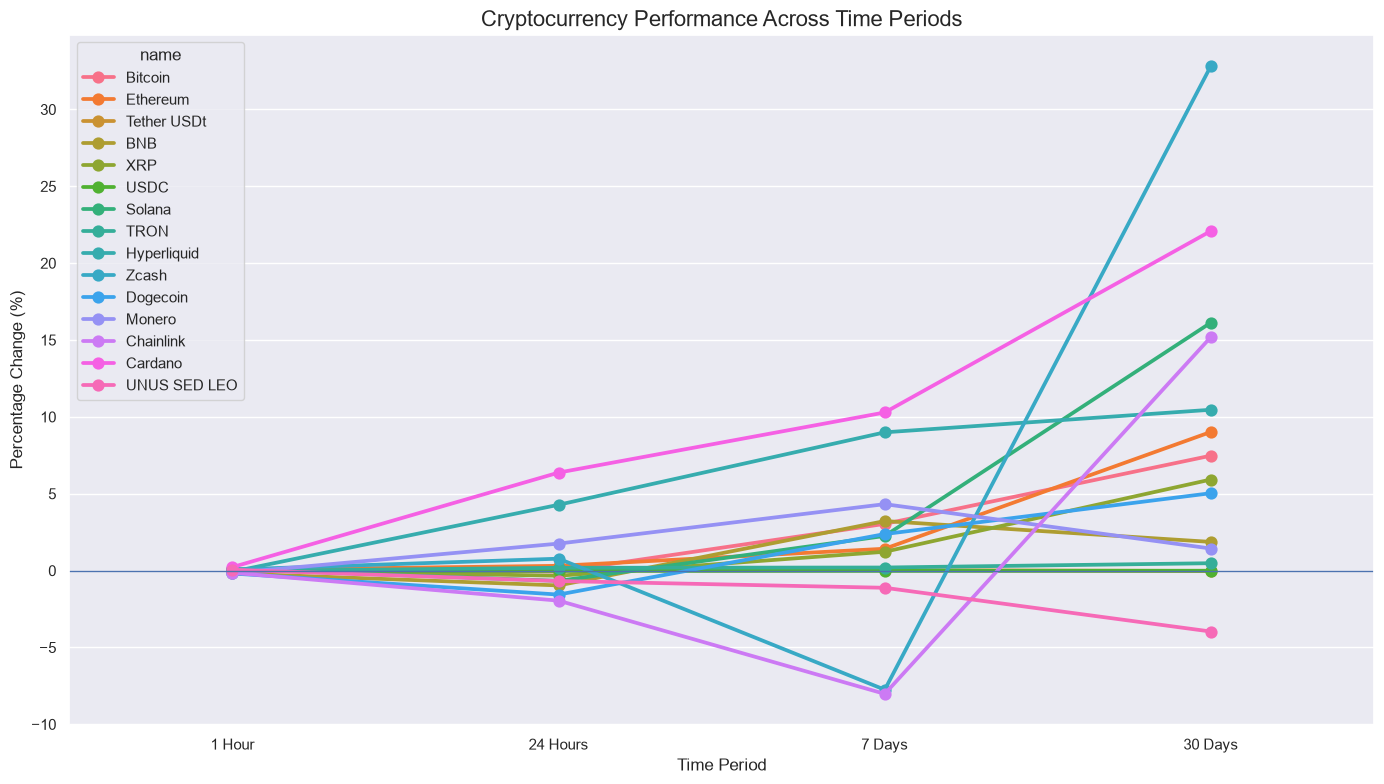

In [34]:
plt.figure(figsize=(14, 8))

sns.pointplot(
    data=performance_long,
    x="period",
    y="percentage_change",
    hue="name"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Cryptocurrency Performance Across Time Periods",
    fontsize=16
)

plt.xlabel("Time Period")
plt.ylabel("Percentage Change (%)")

plt.tight_layout()
plt.show()


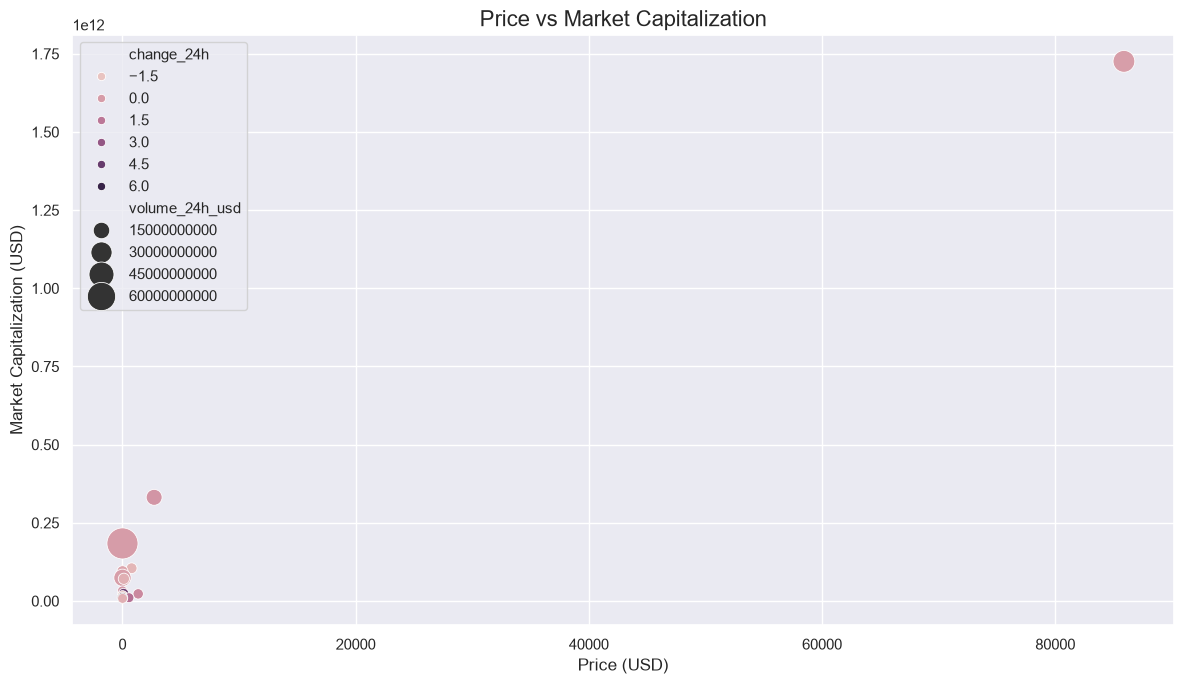

In [35]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=crypto_df,
    x="price_usd",
    y="market_cap_usd",
    size="volume_24h_usd",
    hue="change_24h",
    sizes=(50, 500)
)

plt.title(
    "Price vs Market Capitalization",
    fontsize=16
)

plt.xlabel("Price (USD)")
plt.ylabel("Market Capitalization (USD)")

plt.tight_layout()
plt.show()


In [36]:
correlation_columns = [
    "price_usd",
    "market_cap_usd",
    "volume_24h_usd",
    "change_1h",
    "change_24h",
    "change_7d",
    "change_30d"
]

correlation_matrix = crypto_df[
    correlation_columns
].corr()

correlation_matrix

,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d
price_usd,1.000000,0.983904,0.308370,0.243415,-0.071257,0.089300,-0.013149
market_cap_usd,0.983904,1.000000,0.400297,0.261749,-0.103052,0.092104,-0.053683
volume_24h_usd,0.308370,0.400297,1.000000,0.152343,-0.103785,-0.038338,-0.265379
change_1h,0.243415,0.261749,0.152343,1.000000,0.448216,0.159615,0.413536
change_24h,-0.071257,-0.103052,-0.103785,0.448216,1.000000,0.687344,0.347116
change_7d,0.089300,0.092104,-0.038338,0.159615,0.687344,1.000000,-0.171460
change_30d,-0.013149,-0.053683,-0.265379,0.413536,0.347116,-0.171460,1.000000


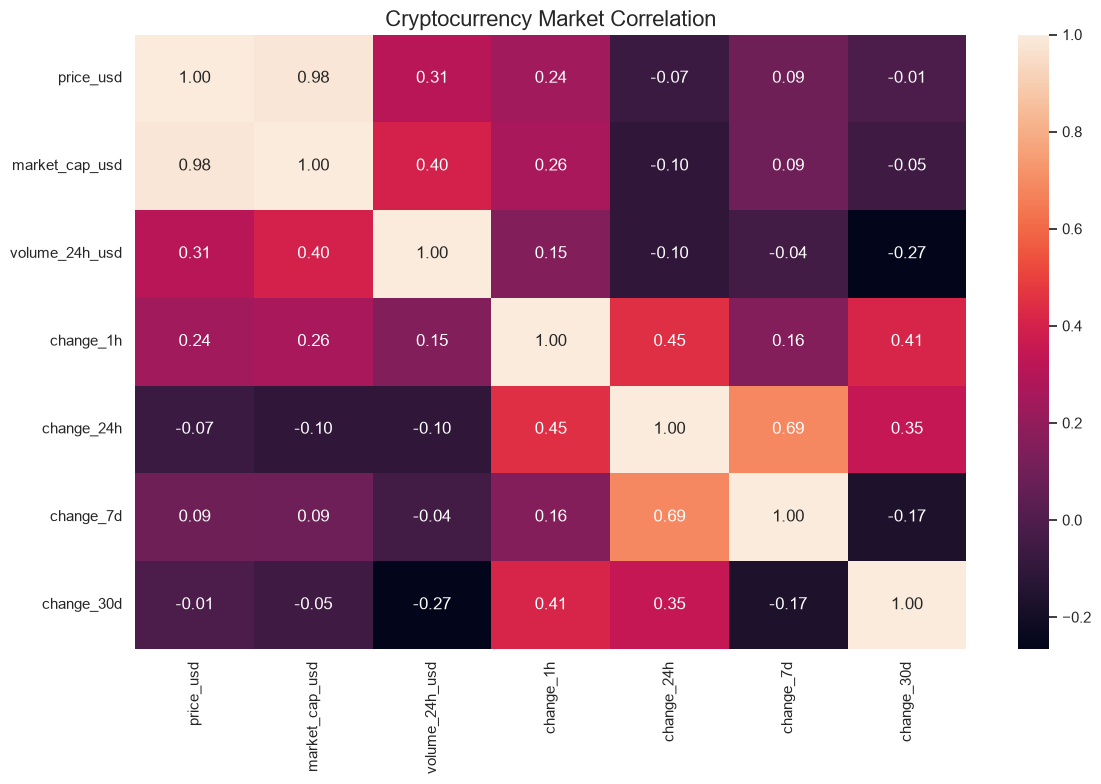

In [37]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Cryptocurrency Market Correlation",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [38]:
DATA_FILE = "crypto_market_history.csv"

print("Data will be saved to:")
print(DATA_FILE)


Data will be saved to:
crypto_market_history.csv


In [39]:
def save_data(df, filename=DATA_FILE):
    
    if df.empty:
        print("No data to save.")
        return
    
    if os.path.exists(filename):
        
        df.to_csv(
            filename,
            mode="a",
            header=False,
            index=False
        )
        
        print("New data appended to existing CSV.")
        
    else:
        
        df.to_csv(
            filename,
            mode="w",
            header=True,
            index=False
        )
        
        print("New CSV file created.")


In [40]:
save_data(crypto_df)


New data appended to existing CSV.


In [41]:
history = pd.read_csv(DATA_FILE)


In [42]:
history.head()


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85889.051797,1.725853e+12,3.232385e+10,0.100806,-0.093743,3.003378,7.545698,2026-10-06 00:40:03.002875
1,1027,Ethereum,ETH,2,2714.585865,3.314714e+11,1.341937e+10,0.031781,0.325754,1.340290,9.348045,2026-10-06 00:40:03.002875
2,825,Tether USDt,USDT,3,0.999728,1.840382e+11,7.420043e+10,-0.008933,-0.009675,0.021961,-0.034283,2026-10-06 00:40:03.002875
3,1839,BNB,BNB,4,786.525356,1.047329e+11,1.691066e+09,-0.202773,-0.891678,3.154032,2.039636,2026-10-06 00:40:03.002875
4,52,XRP,XRP,5,1.505971,9.501622e+10,2.415863e+09,0.052958,-0.354160,0.885705,6.020329,2026-10-06 00:40:03.002875


In [43]:
print("Total historical rows:", len(history))

print(
    "Number of collection timestamps:",
    history["timestamp"].nunique()
)

Total historical rows: 30
Number of collection timestamps: 2


In [44]:
history.tail()

,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
25,74,Dogecoin,DOGE,11,0.095592,1.643371e+10,9.092789e+08,-0.188464,-1.560377,2.376954,5.034932,2026-10-06 00:51:11.400903
26,328,Monero,XMR,12,558.393180,1.050549e+10,1.398342e+08,-0.154349,1.756191,4.322174,1.434867,2026-10-06 00:51:11.400903
27,1975,Chainlink,LINK,13,13.934442,1.042436e+10,2.834088e+08,-0.141055,-1.955737,-8.019710,15.195136,2026-10-06 00:51:11.400903
28,2010,Cardano,ADA,14,0.269224,9.903710e+09,1.336883e+09,0.227178,6.374575,10.286667,22.093191,2026-10-06 00:51:11.400903
29,3957,UNUS SED LEO,LEO,15,8.926511,8.211122e+09,2.628392e+05,0.054521,-0.678086,-1.118310,-3.964529,2026-10-06 00:51:11.400903


In [45]:
history["timestamp"] = pd.to_datetime(
    history["timestamp"]
)


In [46]:
history.dtypes


id                         int64
name                         str
symbol                       str
cmc_rank                   int64
price_usd                float64
market_cap_usd           float64
volume_24h_usd           float64
change_1h                float64
change_24h               float64
change_7d                float64
change_30d               float64
timestamp         datetime64[us]
dtype: object

In [47]:
bitcoin_history = history[
    history["symbol"] == "BTC"
].copy()

In [48]:
bitcoin_history.head()


,id,name,symbol,cmc_rank,price_usd,market_cap_usd,volume_24h_usd,change_1h,change_24h,change_7d,change_30d,timestamp
0,1,Bitcoin,BTC,1,85889.051797,1.725853e+12,3.232385e+10,0.100806,-0.093743,3.003378,7.545698,2026-10-06 00:40:03.002875
15,1,Bitcoin,BTC,1,85887.459169,1.725821e+12,3.232441e+10,0.093566,-0.061572,3.038940,7.476826,2026-10-06 00:51:11.400903


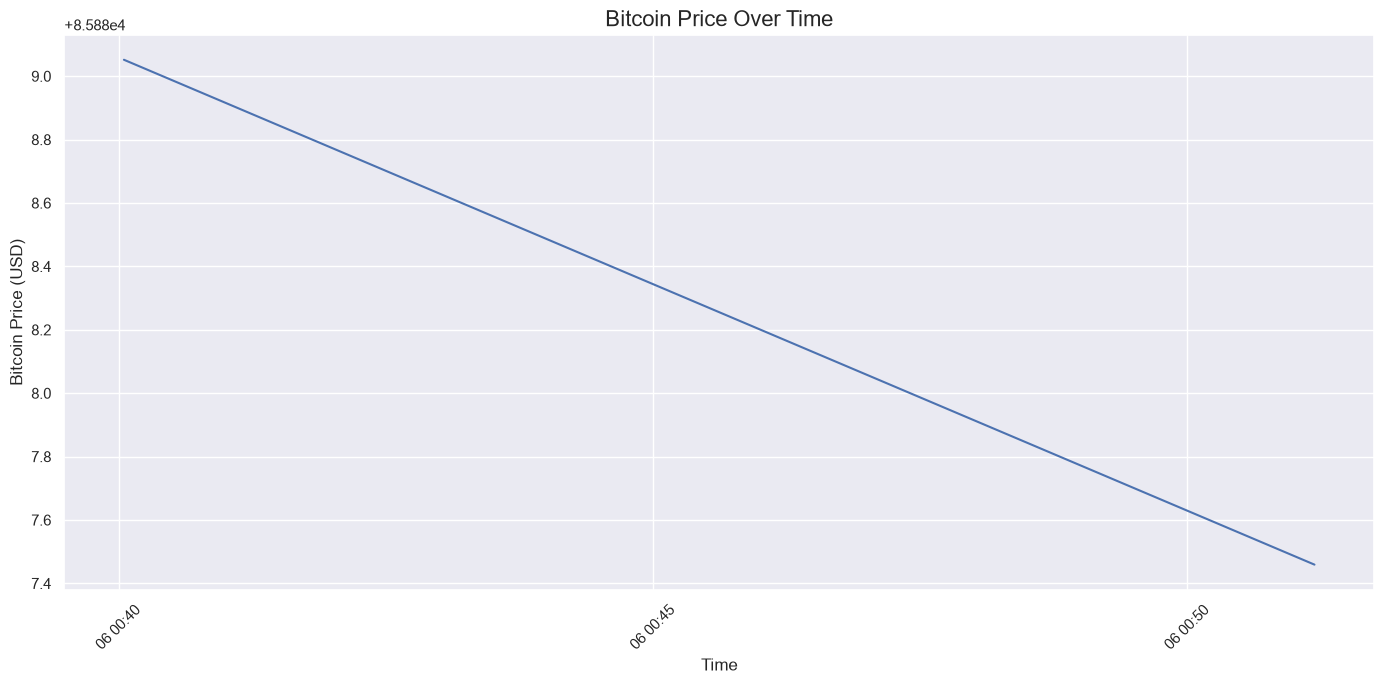

In [49]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=bitcoin_history,
    x="timestamp",
    y="price_usd"
)

plt.title(
    "Bitcoin Price Over Time",
    fontsize=16
)

plt.xlabel("Time")
plt.ylabel("Bitcoin Price (USD)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


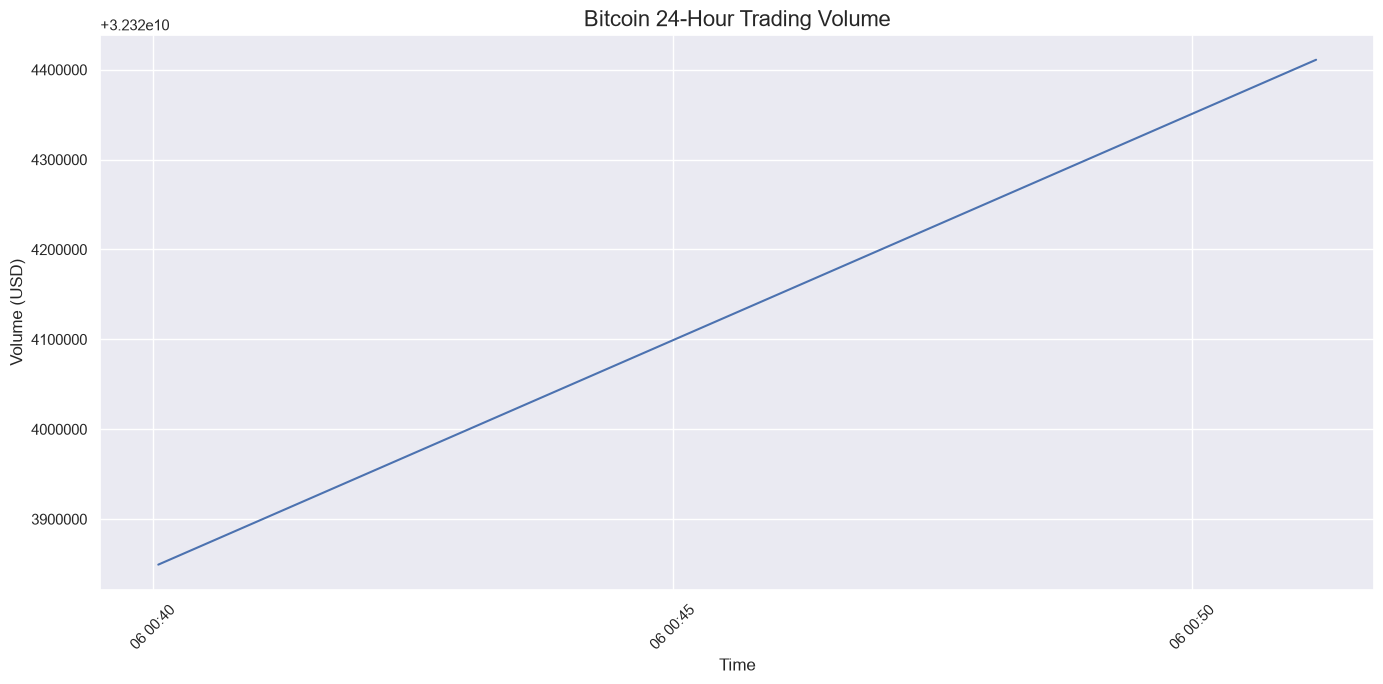

In [50]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=bitcoin_history,
    x="timestamp",
    y="volume_24h_usd"
)

plt.title(
    "Bitcoin 24-Hour Trading Volume",
    fontsize=16
)

plt.xlabel("Time")
plt.ylabel("Volume (USD)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
for i in range(333):
    df = get_crypto_data()
    
    if not df.empty:
        print(f"Collection {i + 1}/333 completed.")
    
    if i < 332:
        sleep(60)

Collection 1/333 completed.
Collection 2/333 completed.
Collection 3/333 completed.


In [ ]:
def collect_crypto_data():
    
    df = get_crypto_data()
    
    if df.empty:
        print("No data collected.")
        return pd.DataFrame()
    
    df["timestamp"] = pd.Timestamp.now()
    
    columns = [
        "id",
        "name",
        "symbol",
        "cmc_rank",
        "quote.USD.price",
        "quote.USD.market_cap",
        "quote.USD.volume_24h",
        "quote.USD.percent_change_1h",
        "quote.USD.percent_change_24h",
        "quote.USD.percent_change_7d",
        "quote.USD.percent_change_30d",
        "timestamp"
    ]
    
    df = df[columns].copy()
    
    df = df.rename(columns={
        "quote.USD.price": "price_usd",
        "quote.USD.market_cap": "market_cap_usd",
        "quote.USD.volume_24h": "volume_24h_usd",
        "quote.USD.percent_change_1h": "change_1h",
        "quote.USD.percent_change_24h": "change_24h",
        "quote.USD.percent_change_7d": "change_7d",
        "quote.USD.percent_change_30d": "change_30d"
    })
    
    df = df.drop_duplicates()
    
    save_data(df)
    
    print(
        f"Collected {len(df)} cryptocurrencies "
        f"at {df['timestamp'].iloc[0]}"
    )
    
    return df


In [ ]:
new_data = collect_crypto_data()

new_data.head()


In [ ]:
def run_collector(
    iterations=10,
    interval_minutes=5
):
    
    for i in range(iterations):
        
        print()
        print("=" * 65)
        print(f"COLLECTION {i + 1} OF {iterations}")
        print("=" * 65)
        
        collect_crypto_data()
        
        if i < iterations - 1:
            
            print()
            print(
                f"Waiting {interval_minutes} minutes..."
            )
            
            sleep(interval_minutes * 60)


In [ ]:
run_collector(
     iterations=5,
     interval_minutes=1
)

In [ ]:
def generate_report(df):
    
    if df.empty:
        print("No data available.")
        return
    
    top_coin = (
        df
        .sort_values(
            "market_cap_usd",
            ascending=False
        )
        .iloc[0]
    )
    
    best_coin = (
        df
        .sort_values(
            "change_24h",
            ascending=False
        )
        .iloc[0]
    )
    
    worst_coin = (
        df
        .sort_values(
            "change_24h"
        )
        .iloc[0]
    )
    
    total_market_cap = df[
        "market_cap_usd"
    ].sum()
    
    total_volume = df[
        "volume_24h_usd"
    ].sum()
    
    print()
    print("=" * 70)
    print("              CRYPTO MARKET ANALYSIS")
    print("=" * 70)
    
    print()
    print(
        f"Cryptocurrencies analyzed : "
        f"{len(df)}"
    )
    
    print(
        f"Total market cap          : "
        f"${total_market_cap:,.2f}"
    )
    
    print(
        f"Total 24h trading volume  : "
        f"${total_volume:,.2f}"
    )
    
    print()
    print("-" * 70)
    print("MARKET LEADER")
    print("-" * 70)
    
    print(
        f"Name       : {top_coin['name']}"
    )
    
    print(
        f"Symbol     : {top_coin['symbol']}"
    )
    
    print(
        f"Price      : ${top_coin['price_usd']:,.2f}"
    )
    
    print(
        f"Market Cap : "
        f"${top_coin['market_cap_usd']:,.2f}"
    )
    
    print()
    print("-" * 70)
    print("BEST 24H PERFORMER")
    print("-" * 70)
    
    print(
        f"{best_coin['name']} "
        f"({best_coin['symbol']})"
    )
    
    print(
        f"24h Change : "
        f"{best_coin['change_24h']:.2f}%"
    )
    
    print()
    print("-" * 70)
    print("WORST 24H PERFORMER")
    print("-" * 70)
    
    print(
        f"{worst_coin['name']} "
        f"({worst_coin['symbol']})"
    )
    
    print(
        f"24h Change : "
        f"{worst_coin['change_24h']:.2f}%"
    )
    
    print()
    print("=" * 70)
    print("                    END OF REPORT")
    print("=" * 70)


In [ ]:
generate_report(crypto_df)


In [ ]:
final_df = crypto_df[
    [
        "cmc_rank",
        "name",
        "symbol",
        "price_usd",
        "market_cap_usd",
        "volume_24h_usd",
        "change_1h",
        "change_24h",
        "change_7d",
        "change_30d",
        "timestamp"
    ]
].copy()

final_df


In [ ]:
final_df.to_csv(
    "crypto_market_latest.csv",
    index=False
)

print("Latest cryptocurrency dataset saved successfully.")

In [ ]:
run_collector(
    iterations=333,
    interval_minutes=1
)